In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. PHYSICAL INPUTS (Measurable Quantities)

In [2]:
M = 1.0
a = 0.95

# USER INPUTS: Defining the orbit using physically measurable parameters
L = 2.0 # Specific Angular Momentum
#L = float(input("Enter a value for L (Specific Angular Momentum): "))
r_initial = 10.0  # Starting radial distance
#r_initial = float(input("Enter a value for initial radial distance from the BH: "))
tau_initial = 0.0
dtau = 0.01
## at r=10.0, the particle plunges for L=2.2228360766

# 2. CALCULATING SPECIFIC ENERGY (E)

In [3]:
# Since u^r = 0 initially, R_eff(r_initial) = 0. We solve the quadratic for E.
alpha = r_initial**3 + (a**2)*r_initial + 2*M*(a**2)
beta = -4 * a * M * L
gamma = -(L**2)*(r_initial - 2*M) - r_initial*(r_initial**2 - 2*M*r_initial + a**2)

discriminant = beta**2 - 4*alpha*gamma
if discriminant < 0:
    raise ValueError(f"No physical orbit exists for L={L} starting from rest at r={r_initial}.")

# Taking the positive energy root
E = (-beta + np.sqrt(discriminant)) / (2 * alpha)
print(f"Calculated Specific Energy (E): {E:.6f}")

Calculated Specific Energy (E): 0.915915


# 3. METRIC & VELOCITY FUNCTIONS

In [4]:
def Sigma(r):
    return r**2 - 2*M*r + a**2

def R_eff(r):
    term1 = (E**2)*(r**3 + (a**2)*r + 2*M*(a**2))
    term2 = -4*a*M*E*L
    term3 = -(L**2) * (r - 2*M)
    term4 = -r * Sigma(r)
    return term1 + term2 + term3 + term4

def dr_dtau(r):
    R_val = R_eff(r)
    if R_val < 0: # Failsafe for unphysical regions
        return 0.0 
    return -np.sqrt(R_val / (r**3))

def get_contravariant_velocities(r, E_val, L_val):
    D = Sigma(r)
    u_phi_contra = (2*a*M*E_val + (r - 2*M)*L_val) / (r * D)
    u_t_contra = ((r**3 + a**2 * r + 2*M*a**2)*E_val - 2*a*M*L_val) / (r * D)
    return u_t_contra, u_phi_contra

# Showing initial velocities to prove the calculation works
ut_init, uphi_init = get_contravariant_velocities(r_initial, E, L)
print(f"Initial Coordinate Velocities: u^t = {ut_init}, u^phi = {uphi_init}")

Initial Coordinate Velocities: u^t = 1.1396861233204219, u^phi = 0.0219279242150597


# 4. RK4 SOLVER WITH NUDGE FIX

In [5]:
tau_vals = []
r_ana_vals = []

# NUDGE: Pushing the particle inward by a microscopic amount so dr/dtau != 0 at step 1
r_current = r_initial - 1e-7
tau_current = tau_initial

max_steps = 100000 
step = 0
horizon = 1.0 + np.sqrt(1.0 - a**2)

while r_current > horizon and step < max_steps:
    tau_vals.append(tau_current)
    r_ana_vals.append(r_current)
    k1 = dr_dtau(r_current)
    if k1 == 0.0 and step > 0:
        print(f"Integration hit a turning point at r = {r_current:.4f}")
        break
    k2 = dr_dtau(r_current + 0.5 * dtau * k1)
    k3 = dr_dtau(r_current + 0.5 * dtau * k2)
    k4 = dr_dtau(r_current + dtau * k3)
    r_current += (dtau / 6.0) * (k1 + 2*k2 + 2*k3 + k4)
    tau_current += dtau
    step += 1

tau_vals = np.array(tau_vals)
r_ana_vals = np.array(r_ana_vals)

# 5. LOAD NUMERICAL DATA & COMPARE

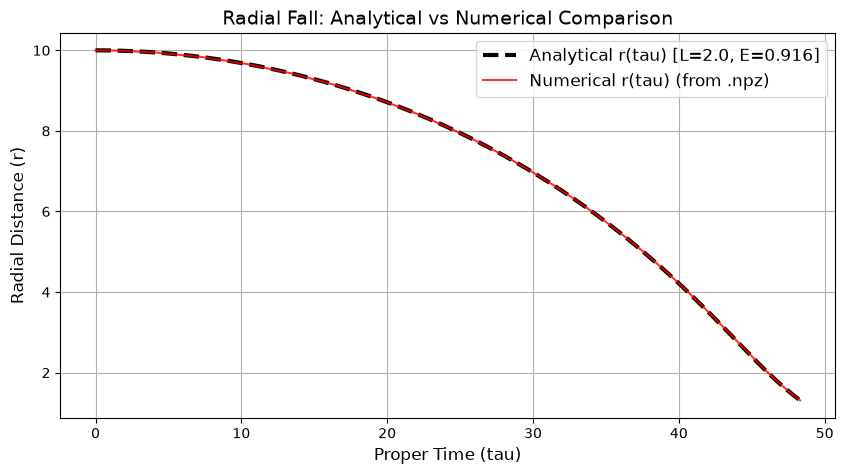

In [6]:
try:
    num_data = np.load('numerical_trajectory_1.npz')
    tau_num = num_data['tau']
    r_num = num_data['r']
    
    plt.figure(figsize=(10, 5))
    plt.plot(tau_vals, r_ana_vals, 'k--', linewidth=3, label=f'Analytical r(tau) [L={L}, E={E:.3f}]')
    plt.plot(tau_num, r_num, 'r', linewidth=1.5, alpha=0.8, label='Numerical r(tau) (from .npz)')
    plt.title("Radial Fall: Analytical vs Numerical Comparison", fontsize=14)
    plt.xlabel("Proper Time (tau)", fontsize=12)
    plt.ylabel("Radial Distance (r)", fontsize=12)
    plt.grid(True)
    plt.legend(fontsize=12)
    plt.show()
    
except FileNotFoundError:
    print("Warning: 'numerical_trajectory_1.npz' not found. Could not plot numerical comparison.")

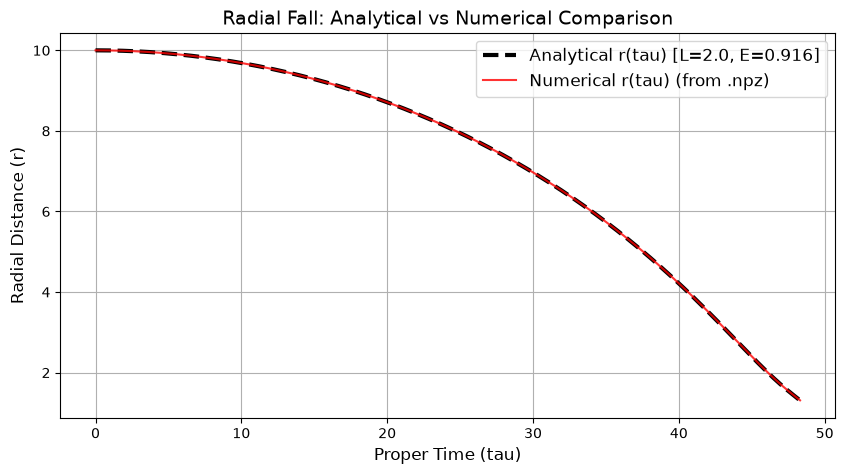

In [7]:
try:
    num_data = np.load('numerical_trajectory_2.npz')
    tau_num = num_data['tau']
    r_num = num_data['r']
    
    plt.figure(figsize=(10, 5))
    plt.plot(tau_vals, r_ana_vals, 'k--', linewidth=3, label=f'Analytical r(tau) [L={L}, E={E:.3f}]')
    plt.plot(tau_num, r_num, 'r', linewidth=1.5, alpha=0.8, label='Numerical r(tau) (from .npz)')
    plt.title("Radial Fall: Analytical vs Numerical Comparison", fontsize=14)
    plt.xlabel("Proper Time (tau)", fontsize=12)
    plt.ylabel("Radial Distance (r)", fontsize=12)
    plt.grid(True)
    plt.legend(fontsize=12)
    plt.show()
    
except FileNotFoundError:
    print("Warning: 'numerical_trajectory_2.npz' not found. Could not plot numerical comparison.")

# 6. CALCULATE AND PLOT RADIAL DIFFERENCE

Maximum radial divergence: 0.0021 at tau = 44.03


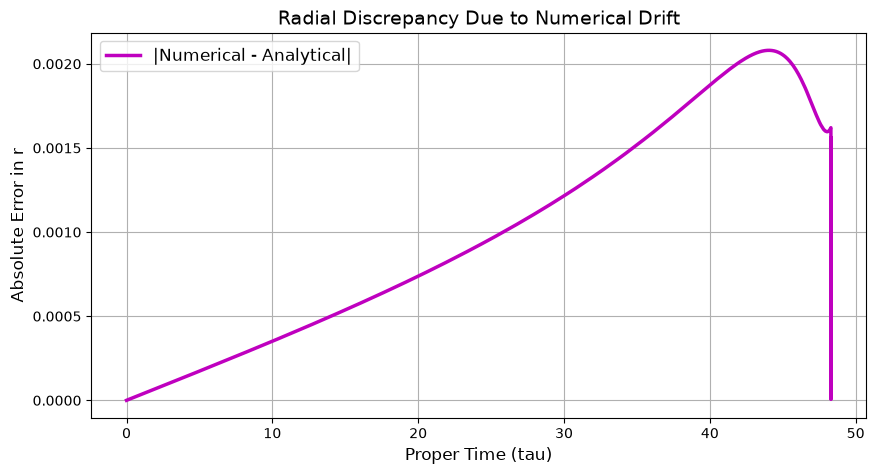

In [8]:
try:
    # Interpolating the analytical radial values onto the numerical time grid
    r_ana_interp = np.interp(tau_num, tau_vals, r_ana_vals)
    
    # Calculating the absolute difference between the numerical and analytical solutions
    radial_difference = np.abs(r_num - r_ana_interp)
    
    # Finding the maximum divergence and exactly when it happens
    max_diff = np.max(radial_difference)
    max_diff_tau = tau_num[np.argmax(radial_difference)]
    print(f"Maximum radial divergence: {max_diff:.4f} at tau = {max_diff_tau:.2f}")
    
    # Plotting the discrepancy
    plt.figure(figsize=(10, 5))
    plt.plot(tau_num, radial_difference, 'm-', linewidth=2.5, label='|Numerical - Analytical|')
    plt.title("Radial Discrepancy Due to Numerical Drift", fontsize=14)
    plt.xlabel("Proper Time (tau)", fontsize=12)
    plt.ylabel("Absolute Error in r", fontsize=12)
    plt.grid(True)
    plt.legend(fontsize=12)
    plt.show()

except NameError:
    print("Numerical data was not loaded, skipping discrepancy calculation.")